# Multi-Modal Lasso Regression for Survival Prediction

This notebook implements an end-to-end multi-modal regularized regression (**LassoCV**) pipeline to predict glioblastoma patient survival (in weeks) from baseline multi-modal data:
- **Clinical**: Demographics (`age_at_t0`, `gender`, `height`, `weight`, `who_performance_status`, `who_guideline`).
- **Treatment**: Radiotherapy timing and dosing (`delay_t0_to_radiotherapy`, `dose`, `fractions_number`).
- **Tumor Volumetrics (RANO)**: Baseline tumor volume at $t_0$ (`size_t0 (cm3)`).
- **PyRadiomics**: Quantitative baseline MRI shape, texture, and intensity features ($t_0$) across imaging sequences.

**Workflow highlights:**
1. **Strict baseline alignment**: Only $t_0$ measurements are used to avoid look-ahead / immortal-time bias.
2. **Independent Holdout Test Set**: A small subset of patients (15%) is partitioned and saved to disk (`test_dataset_holdout.csv`) prior to training.
3. **Cross-Validated Pipeline**: Feature standardization (`StandardScaler`), missingness imputation, and optimal $\alpha$ regularization parameter tuning inside 5-fold CV.
4. **Post-Training Holdout Evaluation**: The model is evaluated on the saved test set simulating unseen clinical data.

## 1. Imports and Environment Setup

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LassoCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("Libraries successfully imported.")

Libraries successfully imported.


## 2. Load Raw Datasets

In [4]:
clinical = pd.read_csv("data/CFB-GBM_clinical_data_v03_20260619.tsv", sep="\t")
treatment = pd.read_csv("data/CFB-GBM_treatment_data_v02_20260129.tsv", sep="\t")
rano = pd.read_csv("data/CFB-GBM_rano_criteria_v04_20260909.tsv", sep="\t")
features = pd.read_csv("data/CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv", sep="\t")

print(f"Clinical shape:   {clinical.shape}")
print(f"Treatment shape:  {treatment.shape}")
print(f"RANO shape:       {rano.shape}")
print(f"Radiomics shape:  {features.shape}")

Clinical shape:   (264, 8)
Treatment shape:  (264, 4)
RANO shape:       (165, 10)
Radiomics shape:  (2424, 150)


## 3. Multi-Modal Feature Harmonization & Alignment

Align multimodal sources at the patient level:
- **Target**: Column 1 of `clinical` (`"survival (weeks)"`).
- **RANO**: Baseline tumor volume only (`size_t0 (cm3)`). Longitudinal response criteria ($t_1, t_2$) are omitted to prevent leakage.
- **PyRadiomics**: Filtered strictly to baseline $t_0$, extracting quantitative features (`original_*`) pivoted across MRI sequences (`t1gd`, `flair`, `adc`).

In [5]:
target_col = clinical.columns[1]  # "survival (weeks)"
id_col = "id_patient"
print(f"Outcome target identified: {target_col}")

# 1. Base table from Clinical
df_master = clinical.copy()

# 2. Merge Treatment Modality
df_master = df_master.merge(treatment, on=id_col, how="left")

# 3. Merge RANO Baseline Tumor Volume (t0 only)
rano_base_cols = [c for c in ["id_patient", "size_t0 (cm3)"] if c in rano.columns]
if len(rano_base_cols) > 1:
    rano_baseline = rano[rano_base_cols].drop_duplicates(subset=[id_col])
    df_master = df_master.merge(rano_baseline, on=id_col, how="left")

# 4. PyRadiomics Baseline (t0 only, pivoted by MRI sequence)
feat_df = features.copy()
if "Patient" in feat_df.columns:
    feat_df = feat_df.rename(columns={"Patient": id_col})

# Restrict strictly to baseline t0
if "Temporality" in feat_df.columns:
    feat_df = feat_df[feat_df["Temporality"] == "t0"]

rad_cols = [c for c in feat_df.columns if c.startswith("original_")]
if rad_cols and "Sequence" in feat_df.columns:
    feat_df[rad_cols] = feat_df[rad_cols].apply(pd.to_numeric, errors="coerce")
    feat_pivot = feat_df.pivot_table(
        index=id_col,
        columns="Sequence",
        values=rad_cols,
        aggfunc="mean"
    )
    feat_pivot.columns = [f"{seq}_{col}" for col, seq in feat_pivot.columns]
    feat_pivot = feat_pivot.reset_index()
    
    # Filter out features with excessive missingness (> 75% missing)
    valid_rad_cols = [id_col] + [c for c in feat_pivot.columns if c != id_col and feat_pivot[c].isna().mean() < 0.75]
    feat_pivot = feat_pivot[valid_rad_cols]
    df_master = df_master.merge(feat_pivot, on=id_col, how="left")

# Filter to patients with valid positive survival recorded
valid_target_mask = df_master[target_col].notna() & (pd.to_numeric(df_master[target_col], errors="coerce") > 0)
clean_df = df_master[valid_target_mask].copy()

print(f"Harmonized patient dataset: {clean_df.shape[0]} patients, {clean_df.shape[1]} total columns.")

Outcome target identified: survival (weeks)
Harmonized patient dataset: 264 patients, 654 total columns.


## 4. Partition and Save Holdout Test Set to Disk

Before any preprocessing or model fitting, we isolate a small holdout test set (e.g., 15% of patients) and save it to disk (`test_dataset_holdout.csv`). This guarantees an independent test set that remains completely untouched during training and tuning.

In [6]:
TEST_RATIO = 0.15
RANDOM_SEED = 42

# Partition into Training set and Holdout Test set
train_df, test_df = train_test_split(
    clean_df, test_size=TEST_RATIO, random_state=RANDOM_SEED
)

# Save holdout test set to disk for post-training validation
test_file_path = "test_dataset_holdout.csv"
test_df.to_csv(test_file_path, index=False)
print(f"Saved holdout test subset ({len(test_df)} patients) to '{test_file_path}'")

# Separate Training predictors and target
y_train = pd.to_numeric(train_df[target_col], errors="coerce")
X_train = train_df.drop(columns=[id_col, target_col])

# Drop uninformative columns (all NaN or constant) using training set only
X_train = X_train.dropna(axis=1, how="all")
valid_predictors = X_train.columns[X_train.nunique() > 1].tolist()
X_train = X_train[valid_predictors]

print(f"Training set ready: {X_train.shape[0]} patients, {X_train.shape[1]} predictor features.")

Saved holdout test subset (40 patients) to 'test_dataset_holdout.csv'
Training set ready: 224 patients, 652 predictor features.


## 5. LassoCV Machine Learning Pipeline

We assemble a scikit-learn `Pipeline` to prevent data leakage across CV folds:
1. **`ColumnTransformer`**:
   - Numeric features: Median imputation + `StandardScaler()` (essential for $L_1$ shrinkage).
   - Categorical features: Mode imputation + `OneHotEncoder(drop="first")`.
2. **`LassoCV`**: 5-Fold Cross-Validation over an exponential grid of $\alpha$ penalty strengths.

In [7]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()

print(f"Numeric predictor features:     {len(num_cols)}")
print(f"Categorical predictor features: {len(cat_cols)}")

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols)
    ],
    remainder="drop"
)

cv_folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
alphas_search = np.logspace(-3, 2, 100)

lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("lasso", LassoCV(alphas=alphas_search, cv=cv_folds, max_iter=10000, random_state=RANDOM_SEED))
])

# Fit pipeline strictly on training data
lasso_pipeline.fit(X_train, y_train)

best_alpha = lasso_pipeline.named_steps["lasso"].alpha_
print(f"Optimal Lasso Regularization Alpha (CV): {best_alpha:.5f}")

Numeric predictor features:     651
Categorical predictor features: 1
Optimal Lasso Regularization Alpha (CV): 3.05386


## 6. Post-Training Evaluation on Saved Test Set

We now load the saved holdout test file (`test_dataset_holdout.csv`) from disk to evaluate model generalization on unseen patient data.

Loaded holdout test file: 40 patients


,Train,Saved Test Set (Holdout)
R² Score,0.333,0.051
RMSE (weeks),34.846,43.719
MAE (weeks),25.770,32.785


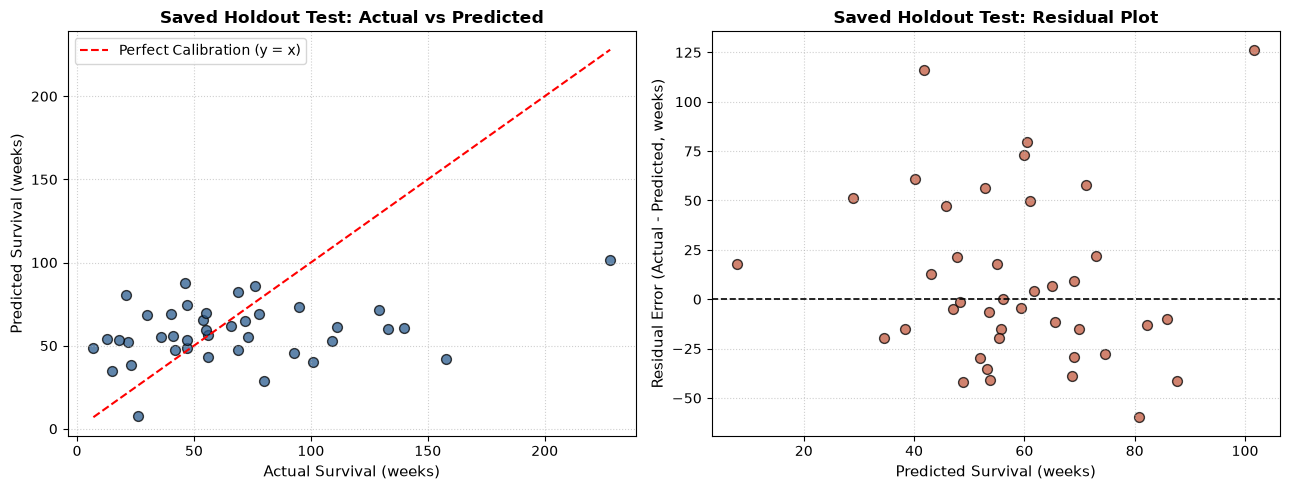

In [8]:
# Load the saved test dataset from disk
saved_test_df = pd.read_csv("test_dataset_holdout.csv")
print(f"Loaded holdout test file: {saved_test_df.shape[0]} patients")

# Extract predictor matrix using the training columns and target
X_test = saved_test_df[valid_predictors]
y_test = pd.to_numeric(saved_test_df[target_col], errors="coerce")

# Predictions
y_train_pred = lasso_pipeline.predict(X_train)
y_test_pred = lasso_pipeline.predict(X_test)

metrics_df = pd.DataFrame({
    "Train": [
        r2_score(y_train, y_train_pred),
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        mean_absolute_error(y_train, y_train_pred)
    ],
    "Saved Test Set (Holdout)": [
        r2_score(y_test, y_test_pred),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        mean_absolute_error(y_test, y_test_pred)
    ]
}, index=["R² Score", "RMSE (weeks)", "MAE (weeks)"])

display(metrics_df.round(3))

# Diagnostic plots on the saved test set
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs. Predicted
axes[0].scatter(y_test, y_test_pred, color="#2b5c8f", edgecolors="k", alpha=0.75, s=50)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Perfect Calibration (y = x)")
axes[0].set_xlabel("Actual Survival (weeks)", fontsize=11)
axes[0].set_ylabel("Predicted Survival (weeks)", fontsize=11)
axes[0].set_title("Saved Holdout Test: Actual vs Predicted", fontsize=12, fontweight="bold")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Residuals
residuals = y_test - y_test_pred
axes[1].scatter(y_test_pred, residuals, color="#c2593f", edgecolors="k", alpha=0.75, s=50)
axes[1].axhline(0, color="black", linestyle="--", lw=1.2)
axes[1].set_xlabel("Predicted Survival (weeks)", fontsize=11)
axes[1].set_ylabel("Residual Error (Actual - Predicted, weeks)", fontsize=11)
axes[1].set_title("Saved Holdout Test: Residual Plot", fontsize=12, fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Selected Biomarkers (Lasso Feature Selection)

Lasso drives coefficients of uninformative features to zero. Here we inspect the retained non-zero predictors.

Total features in model:       652
Selected non-zero biomarkers:  24


,Feature,Coefficient
502,flair_original_glszm_SmallAreaEmphasis,8.4559
578,t2tse_original_shape_Flatness,5.5476
6,dose (Gy),4.3248
0,age_at_t0 (years),-3.7482
474,t1gd_original_glszm_LargeAreaHighGrayLevelEmph...,3.3046
2,who_guideline,-2.9292
215,t1eg_original_glcm_JointAverage,2.6743
5,delay_t0_to_radiotherapy (weeks),2.2383
8,size_t0 (cm3),2.0889
64,flair_original_firstorder_Median,2.0177


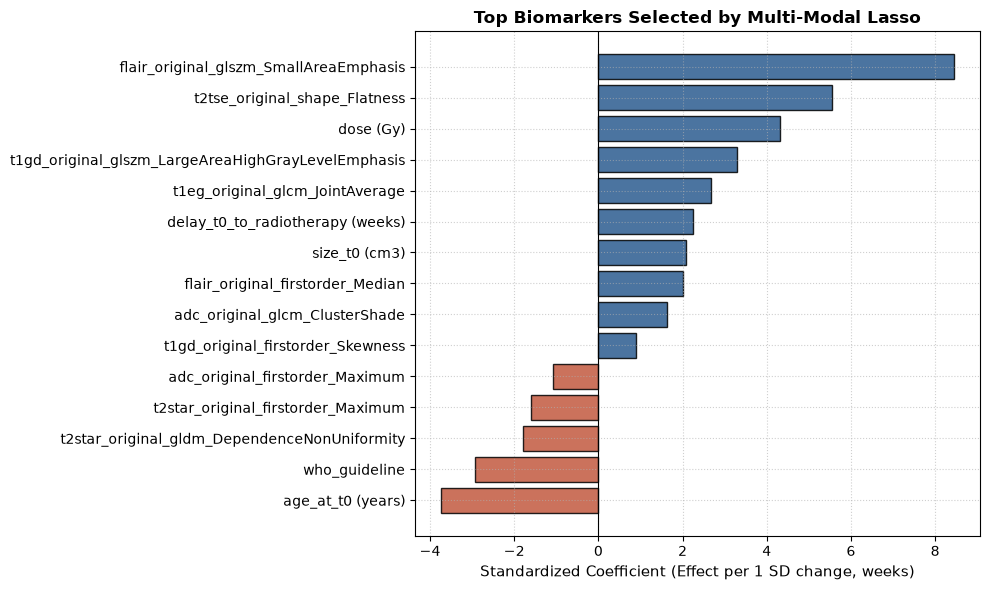

In [9]:
raw_feature_names = lasso_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_names = [f.split("__")[-1] for f in raw_feature_names]
coefs = lasso_pipeline.named_steps["lasso"].coef_

coef_df = pd.DataFrame({
    "Feature": clean_names,
    "Coefficient": coefs,
    "Abs_Coefficient": np.abs(coefs)
}).sort_values("Abs_Coefficient", ascending=False)

selected = coef_df[coef_df["Coefficient"] != 0].copy()
print(f"Total features in model:       {len(clean_names)}")
print(f"Selected non-zero biomarkers:  {len(selected)}")

if not selected.empty:
    display(selected[["Feature", "Coefficient"]].head(20).round(4))
    
    # Visualize top 15 selected features
    top_n = selected.head(15).sort_values("Coefficient", ascending=True)
    colors = ["#2b5c8f" if c > 0 else "#c2593f" for c in top_n["Coefficient"]]
    
    plt.figure(figsize=(10, 6))
    plt.barh(top_n["Feature"], top_n["Coefficient"], color=colors, edgecolor="black", alpha=0.85)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("Standardized Coefficient (Effect per 1 SD change, weeks)", fontsize=11)
    plt.title("Top Biomarkers Selected by Multi-Modal Lasso", fontsize=12, fontweight="bold")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()
else:
    print("All coefficients shrunk to zero. Try expanding the alpha search grid.")

## 8. Log-Transformed Survival Pipeline (Biostatistical Best Practice)

Survival data is right-skewed and strictly positive. Fitting Lasso on $\log(1 + y)$ guarantees strictly positive predicted survival times and stabilizes the residual variance.

In [10]:
log_lasso_model = TransformedTargetRegressor(
    regressor=LassoCV(alphas=alphas_search, cv=cv_folds, max_iter=10000, random_state=RANDOM_SEED),
    func=np.log1p,
    inverse_func=np.expm1
)

log_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("log_lasso", log_lasso_model)
])

log_pipeline.fit(X_train, y_train)
y_test_pred_log = log_pipeline.predict(X_test)

comparison_df = pd.DataFrame({
    "Linear Lasso": [
        r2_score(y_test, y_test_pred),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        mean_absolute_error(y_test, y_test_pred)
    ],
    "Log-Transformed Lasso": [
        r2_score(y_test, y_test_pred_log),
        np.sqrt(mean_squared_error(y_test, y_test_pred_log)),
        mean_absolute_error(y_test, y_test_pred_log)
    ]
}, index=["Test R² Score", "Test RMSE (weeks)", "Test MAE (weeks)"])

print("Model Comparison on Saved Holdout Test Set:")
display(comparison_df.round(3))

# Check for negative predictions in linear model vs log model
neg_linear = (y_test_pred < 0).sum()
neg_log = (y_test_pred_log < 0).sum()
print(f"Negative survival predictions on test set — Linear: {neg_linear}, Log-Transformed: {neg_log}")

Model Comparison on Saved Holdout Test Set:


,Linear Lasso,Log-Transformed Lasso
Test R² Score,0.051,-0.135
Test RMSE (weeks),43.719,47.805
Test MAE (weeks),32.785,34.774


Negative survival predictions on test set — Linear: 0, Log-Transformed: 0
